In [ ]:
h!nvidia-smi
!pip install -q opencv-contrib-python torchmetrics pycocotools roboflow ultralytics

/bin/bash: line 1: nvidia-smi: command not found
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 32.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 324.6/324.6 kB 18.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 51.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 83.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.0/91.0 kB 6.3 MB/s eta 0:00:00


In [ ]:
import cv2
print(hasattr(cv2, "ximgproc"))   # must print True

True


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import os

project_path = "/content/drive/MyDrive/ppe"

print("Project exists:", os.path.exists(project_path))
print("\nContents:")
print(os.listdir(project_path))

Project exists: True

Contents:
['construction-ppe.zip']


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/ppe/construction-ppe.zip"
extract_path = "/content/drive/MyDrive/ppe"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")

Extraction completed!


In [ ]:
import os

project_path = "/content/drive/MyDrive/ppe"

for root, dirs, files in os.walk(project_path):
    level = root.replace(project_path, "").count(os.sep)

    if level > 3:
        continue

    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

ppe/
  images/
    test/
    train/
    val/
  labels/
    test/
    train/
    val/


In [ ]:
import os

base_path = "/content/drive/MyDrive/ppe"

print(os.listdir(base_path))

['construction-ppe.zip', 'images', 'labels', 'data.yaml', 'LICENSE']


In [ ]:
dataset_path = "/content/drive/MyDrive/ppe"

In [ ]:
import os

dataset_path = "/content/drive/MyDrive/ppe"

print("Images:", os.listdir(dataset_path + "/images"))
print("Labels:", os.listdir(dataset_path + "/labels"))

Images: ['test', 'train', 'val']
Labels: ['test', 'train', 'val']


In [ ]:
import glob
import os

dataset_path = "/content/drive/MyDrive/ppe"

label_files = glob.glob(
    dataset_path + "/labels/train/*.txt"
)

print("Training label files:", len(label_files))

print("\nFirst label file:")
print(label_files[0])

with open(label_files[0], "r") as f:
    print(f.read())

Training label files: 1142

First label file:
/content/drive/MyDrive/ppe/labels/train/image100.txt
0 0.421102 0.383109 0.101734 0.082469
0 0.245664 0.380945 0.119266 0.078141
6 0.218617 0.540047 0.216234 0.456500
6 0.399352 0.550867 0.227484 0.448266
6 0.760930 0.529328 0.240266 0.482688
6 0.588852 0.549891 0.225109 0.450219
5 0.221859 0.571422 0.214062 0.303250
5 0.412445 0.595133 0.183984 0.316016
5 0.756383 0.597406 0.222953 0.346531
0 0.729438 0.372289 0.117094 0.095016
0 0.553031 0.362555 0.110594 0.071641



In [ ]:
import glob
import os

yaml_files = glob.glob("/content/drive/MyDrive/ppe/*.yaml")

print(yaml_files)

['/content/drive/MyDrive/ppe/data.yaml']


In [ ]:
yaml_path = yaml_files[0]

with open(yaml_path, "r") as f:
    print(f.read())

# Ultralytics 🚀 AGPL-3.0 License - https://ultralytics.com/license

# Construction-PPE dataset by Ultralytics
# Documentation: https://docs.ultralytics.com/datasets/detect/construction-ppe/
# Example usage: yolo train data=construction-ppe.yaml
# parent
# ├── ultralytics
# └── datasets
#     └── construction-ppe ← downloads here (178.4 MB)

# Train/val/test sets as 1) dir: path/to/imgs, 2) file: path/to/imgs.txt, or 3) list: [path/to/imgs1, path/to/imgs2, ..]
path: construction-ppe # dataset root dir
train: images/train # train images (relative to 'path') 1132 images
val: images/val # val images (relative to 'path') 143 images
test: images/test # test images (relative to 'path') 141 images

# Classes
names:
  0: helmet
  1: gloves
  2: vest
  3: boots
  4: goggles
  5: none
  6: Person
  7: no_helmet
  8: no_goggle
  9: no_gloves
  10: no_boots

# Download script/URL (optional)
download: https://github.com/ultralytics/assets/releases/download/v0.0.0/construction-ppe.zip




In [ ]:
from PIL import Image
import os

dataset_path = "/content/drive/MyDrive/ppe"

image_path = os.path.join(
    dataset_path,
    "images/train/image100.jpg"
)

label_path = os.path.join(
    dataset_path,
    "labels/train/image100.txt"
)

image = Image.open(image_path)

print("Image size:", image.size)
print("Image mode:", image.mode)

print("\nAnnotation:")
with open(label_path, "r") as f:
    print(f.read())

Image size: (640, 640)
Image mode: RGB

Annotation:
0 0.421102 0.383109 0.101734 0.082469
0 0.245664 0.380945 0.119266 0.078141
6 0.218617 0.540047 0.216234 0.456500
6 0.399352 0.550867 0.227484 0.448266
6 0.760930 0.529328 0.240266 0.482688
6 0.588852 0.549891 0.225109 0.450219
5 0.221859 0.571422 0.214062 0.303250
5 0.412445 0.595133 0.183984 0.316016
5 0.756383 0.597406 0.222953 0.346531
0 0.729438 0.372289 0.117094 0.095016
0 0.553031 0.362555 0.110594 0.071641



In [ ]:
import os
import torch
from PIL import Image
from torch.utils.data import Dataset


class ConstructionPPEDataset(Dataset):

    def __init__(self, root_dir, split="train"):
        self.root_dir = root_dir
        self.split = split

        self.image_dir = os.path.join(
            root_dir, "images", split
        )

        self.label_dir = os.path.join(
            root_dir, "labels", split
        )

        self.image_files = sorted([
            f for f in os.listdir(self.image_dir)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):

        # -------------------------
        # 1. Image
        # -------------------------
        image_name = self.image_files[idx]

        image_path = os.path.join(
            self.image_dir,
            image_name
        )

        image = Image.open(image_path).convert("RGB")

        width, height = image.size

        # -------------------------
        # 2. Label file
        # -------------------------
        label_name = os.path.splitext(image_name)[0] + ".txt"

        label_path = os.path.join(
            self.label_dir,
            label_name
        )

        boxes = []
        labels = []

        with open(label_path, "r") as f:

            for line in f:

                values = line.strip().split()

                if len(values) != 5:
                    continue

                class_id = int(values[0])

                x_center = float(values[1])
                y_center = float(values[2])
                box_width = float(values[3])
                box_height = float(values[4])

                # -------------------------
                # 3. YOLO → pixel coordinates
                # -------------------------

                x_center *= width
                y_center *= height
                box_width *= width
                box_height *= height

                x_min = x_center - box_width / 2
                y_min = y_center - box_height / 2
                x_max = x_center + box_width / 2
                y_max = y_center + box_height / 2

                # Keep boxes inside image
                x_min = max(0, x_min)
                y_min = max(0, y_min)
                x_max = min(width, x_max)
                y_max = min(height, y_max)

                # Ignore invalid boxes
                if x_max <= x_min or y_max <= y_min:
                    continue

                boxes.append([
                    x_min,
                    y_min,
                    x_max,
                    y_max
                ])

                # Faster R-CNN reserves label 0 for background.
                labels.append(class_id + 1)

        # -------------------------
        # 4. Convert to tensors
        # -------------------------

        boxes = torch.as_tensor(
            boxes,
            dtype=torch.float32
        )

        labels = torch.as_tensor(
            labels,
            dtype=torch.int64
        )

        # -------------------------
        # 5. Faster R-CNN target
        # -------------------------

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([idx])
        }

        # PIL → Tensor
        image = torch.from_numpy(
            __import__("numpy").array(image)
        )

        image = image.permute(2, 0, 1).float() / 255.0

        return image, target

In [ ]:
dataset_path = "/content/drive/MyDrive/ppe"

train_dataset = ConstructionPPEDataset(
    dataset_path,
    split="train"
)

print("Dataset size:", len(train_dataset))

image, target = train_dataset[0]

print("Image shape:", image.shape)
print("Boxes shape:", target["boxes"].shape)
print("Labels:", target["labels"])
print("Boxes:")
print(target["boxes"])

Dataset size: 1132
Image shape: torch.Size([3, 640, 640])
Boxes shape: torch.Size([11, 4])
Labels: tensor([1, 1, 7, 7, 7, 7, 6, 6, 6, 1, 1])
Boxes:
tensor([[236.9504, 218.7997, 302.0602, 271.5798],
        [119.0598, 218.7997, 195.3901, 268.8099],
        [ 70.7200, 199.5501, 209.1098, 491.7101],
        [182.7904, 209.1098, 328.3802, 496.0000],
        [410.1101, 184.3098, 563.8803, 493.2301],
        [304.8304, 207.8602, 448.9001, 496.0003],
        [ 73.4899, 268.6701, 210.4896, 462.7501],
        [205.0899, 279.7600, 322.8397, 482.0103],
        [412.7402, 271.4499, 555.4301, 493.2298],
        [429.3702, 207.8598, 504.3104, 268.6701],
        [318.5498, 209.1101, 389.3299, 254.9603]])


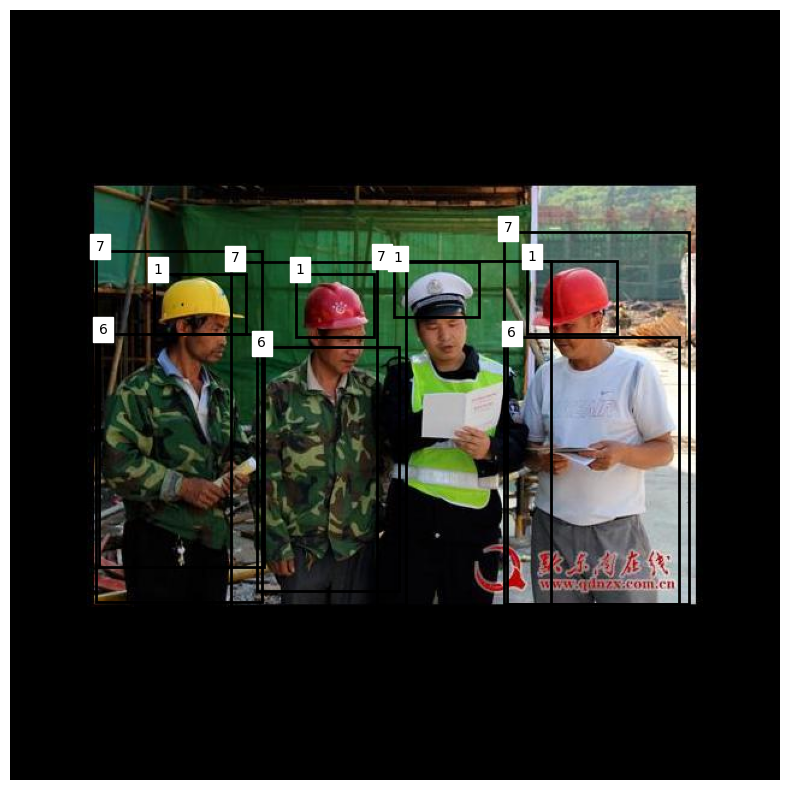

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

image, target = train_dataset[0]

# Convert CHW -> HWC for plotting
image_np = image.permute(1, 2, 0).numpy()

fig, ax = plt.subplots(figsize=(10, 10))

ax.imshow(image_np)

for box, label in zip(target["boxes"], target["labels"]):

    x_min, y_min, x_max, y_max = box.tolist()

    rect = patches.Rectangle(
        (x_min, y_min),
        x_max - x_min,
        y_max - y_min,
        fill=False,
        linewidth=2
    )

    ax.add_patch(rect)

    ax.text(
        x_min,
        y_min,
        str(label.item()),
        fontsize=10,
        backgroundcolor="white"
    )

ax.axis("off")
plt.show()

In [ ]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()

print(
    f"GPU memory allocated: "
    f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
)

print(
    f"GPU memory reserved: "
    f"{torch.cuda.memory_reserved() / 1024**3:.2f} GB"
)

GPU memory allocated: 0.16 GB
GPU memory reserved: 0.17 GB


In [ ]:
# YOLO → Faster R-CNN annotation conversion is working correctly ** aster R-CNN has a special requirement: each image can have a different number of bounding boxes, so we can't use the default PyTorch batching.
# data loader

In [ ]:
from torch.utils.data import DataLoader

def collate_fn(batch):
    return tuple(zip(*batch))


train_loader = DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=2
)

print("Number of batches:", len(train_loader))

Number of batches: 1132


In [ ]:
images, targets = next(iter(train_loader))

print("Number of images:", len(images))
print("First image shape:", images[0].shape)
print("First target:", targets[0])

Number of images: 1
First image shape: torch.Size([3, 768, 1024])
First target: {'boxes': tensor([[ 513.0721,  244.9440,  668.9761,  304.9916],
        [ 437.2157,  499.3682,  576.2719,  602.0882],
        [ 371.9040,  414.0361,  470.9279,  519.9118],
        [ 632.3041,  164.3044,  996.4805,  561.4080],
        [ 374.2884,  316.4882,  833.8719,  672.2765],
        [ 878.2239,  302.3758, 1023.9995,  413.2435],
        [ 491.9998,  181.7403,  709.0233,  309.7321],
        [ 668.5927,  124.2962,  982.8961,  553.5959],
        [ 338.4965,  169.0679,  844.1764,  665.5315]]), 'labels': tensor([ 9, 10, 10,  6,  6,  2,  8,  7,  7]), 'image_id': tensor([107])}


In [ ]:
import torch
import torchvision
from torchvision.models.detection import fasterrcnn_resnet50_fpn

num_classes = 12

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = fasterrcnn_resnet50_fpn(
    weights=None,
    weights_backbone=None,
    num_classes=num_classes,
    min_size=512,
    max_size=512
)

model = model.to(device)

print("Torchvision:", torchvision.__version__)
print("Device:", device)
print("Number of classes:", num_classes)

Torchvision: 0.26.0+cu128
Device: cuda
Number of classes: 12


In [ ]:
print(
    f"GPU allocated: "
    f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
)

print(
    f"GPU reserved: "
    f"{torch.cuda.memory_reserved() / 1024**3:.2f} GB"
)

GPU allocated: 0.32 GB
GPU reserved: 0.33 GB


In [ ]:
print(model)

FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(512,), max_size=512, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        

In [ ]:
print("Model created successfully")
print("Device:", next(model.parameters()).device)

Model created successfully
Device: cuda:0


In [ ]:
model.eval()

images, targets = next(iter(train_loader))

images = [image.to(device) for image in images]
targets = [
    {key: value.to(device) for key, value in target.items()}
    for target in targets
]

with torch.no_grad():
    predictions = model(images)

print("Number of predictions:", len(predictions))
print("First prediction keys:", predictions[0].keys())
print("Boxes shape:", predictions[0]["boxes"].shape)
print("Labels shape:", predictions[0]["labels"].shape)
print("Scores shape:", predictions[0]["scores"].shape)

Number of predictions: 1
First prediction keys: dict_keys(['boxes', 'labels', 'scores'])
Boxes shape: torch.Size([100, 4])
Labels shape: torch.Size([100])
Scores shape: torch.Size([100])


In [ ]:
import os
import torch
import numpy as np
from PIL import Image
from torch.utils.data import Dataset


class ConstructionPPEDataset(Dataset):

    def __init__(self, root_dir, split="train"):
        self.root_dir = root_dir
        self.split = split

        self.image_dir = os.path.join(root_dir, "images", split)
        self.label_dir = os.path.join(root_dir, "labels", split)

        self.image_files = sorted([
            f for f in os.listdir(self.image_dir)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):

        image_name = self.image_files[idx]

        image_path = os.path.join(
            self.image_dir,
            image_name
        )

        image = Image.open(image_path).convert("RGB")

        width, height = image.size

        label_name = os.path.splitext(image_name)[0] + ".txt"

        label_path = os.path.join(
            self.label_dir,
            label_name
        )

        boxes = []
        labels = []

        # Read YOLO annotations
        if os.path.exists(label_path):

            with open(label_path, "r") as f:

                for line in f:

                    values = line.strip().split()

                    if len(values) != 5:
                        continue

                    class_id = int(values[0])

                    x_center = float(values[1])
                    y_center = float(values[2])
                    box_width = float(values[3])
                    box_height = float(values[4])

                    # YOLO normalized coordinates
                    # → pixel coordinates

                    x_center *= width
                    y_center *= height
                    box_width *= width
                    box_height *= height

                    x_min = x_center - box_width / 2
                    y_min = y_center - box_height / 2

                    x_max = x_center + box_width / 2
                    y_max = y_center + box_height / 2

                    # Keep boxes inside image
                    x_min = max(0, x_min)
                    y_min = max(0, y_min)
                    x_max = min(width, x_max)
                    y_max = min(height, y_max)

                    # Ignore invalid boxes
                    if x_max <= x_min or y_max <= y_min:
                        continue

                    boxes.append([
                        x_min,
                        y_min,
                        x_max,
                        y_max
                    ])

                    # Faster R-CNN:
                    # 0 = background
                    # Dataset classes start from 1

                    labels.append(class_id + 1)

        # Important:
        # Faster R-CNN expects [N, 4]
        # even when N = 0

        if len(boxes) == 0:

            boxes = torch.zeros(
                (0, 4),
                dtype=torch.float32
            )

            labels = torch.zeros(
                (0,),
                dtype=torch.int64
            )

        else:

            boxes = torch.tensor(
                boxes,
                dtype=torch.float32
            )

            labels = torch.tensor(
                labels,
                dtype=torch.int64
            )

        # Calculate area of every bounding box

        area = (
            (boxes[:, 2] - boxes[:, 0]) *
            (boxes[:, 3] - boxes[:, 1])
        )

        # No crowd annotations in our dataset

        iscrowd = torch.zeros(
            (len(boxes),),
            dtype=torch.int64
        )

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor(
                [idx],
                dtype=torch.int64
            ),
            "area": area,
            "iscrowd": iscrowd
        }

        # Convert image to Tensor
        image = torch.from_numpy(
            np.array(image)
        )

        # HWC → CHW
        image = image.permute(2, 0, 1)

        # uint8 [0,255] → float [0,1]
        image = image.float() / 255.0

        return image, target

In [ ]:
dataset_path = "/content/drive/MyDrive/ppe"

train_dataset = ConstructionPPEDataset(
    dataset_path,
    split="train"
)

print("Dataset size:", len(train_dataset))

Dataset size: 1132


In [ ]:
image, target = train_dataset[0]

print("Image shape:", image.shape)
print("Boxes shape:", target["boxes"].shape)
print("Labels:", target["labels"])
print("Area shape:", target["area"].shape)
print("iscrowd shape:", target["iscrowd"].shape)

Image shape: torch.Size([3, 640, 640])
Boxes shape: torch.Size([11, 4])
Labels: tensor([1, 1, 7, 7, 7, 7, 6, 6, 6, 1, 1])
Area shape: torch.Size([11])
iscrowd shape: torch.Size([11])


In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=2
)

print("Batches:", len(train_loader))

Batches: 1132


In [ ]:
images, targets = next(iter(train_loader))

print("Batch size:", len(images))
print("First image:", images[0].shape)
print("First boxes:", targets[0]["boxes"].shape)
print("First labels:", targets[0]["labels"].shape)
print("First area:", targets[0]["area"].shape)
print("First iscrowd:", targets[0]["iscrowd"].shape)

Batch size: 4
First image: torch.Size([3, 640, 640])
First boxes: torch.Size([8, 4])
First labels: torch.Size([8])
First area: torch.Size([8])
First iscrowd: torch.Size([8])


In [ ]:
params = [
    p for p in model.parameters()
    if p.requires_grad
]

optimizer = torch.optim.SGD(
    params,
    lr=0.005,
    momentum=0.9,
    weight_decay=0.0005
)

lr_scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=3,
    gamma=0.1
)

print("Optimizer ready")

Optimizer ready


In [ ]:
#learing rate scheduler

lr_scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=3,
    gamma=0.1
)

print("Initial learning rate:",
      optimizer.param_groups[0]["lr"])

Initial learning rate: 0.005


In [ ]:
model.train()

images, targets = next(iter(train_loader))

images = [
    image.to(device)
    for image in images
]

targets = [
    {
        key: value.to(device)
        for key, value in target.items()
    }
    for target in targets
]

loss_dict = model(images, targets)

losses = sum(loss for loss in loss_dict.values())

print("Loss components:")

for name, loss in loss_dict.items():
    print(f"{name}: {loss.item():.4f}")

print(f"Total loss: {losses.item():.4f}")

print(
    f"GPU allocated: "
    f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
)

print(
    f"GPU reserved: "
    f"{torch.cuda.memory_reserved() / 1024**3:.2f} GB"
)

Loss components:
loss_classifier: 2.3137
loss_box_reg: 0.2742
loss_objectness: 0.7321
loss_rpn_box_reg: 0.6505
Total loss: 3.9706
GPU allocated: 0.68 GB
GPU reserved: 0.79 GB


In [ ]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()

print(
    f"GPU allocated: "
    f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
)

print(
    f"GPU reserved: "
    f"{torch.cuda.memory_reserved() / 1024**3:.2f} GB"
)

GPU allocated: 13.98 GB
GPU reserved: 14.34 GB


In [ ]:
import gc
import torch

for name in ["model", "optimizer", "lr_scheduler"]:
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()

print(f"GPU allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")
print(f"GPU reserved: {torch.cuda.memory_reserved() / 1024**3:.2f} GB")

GPU allocated: 0.00 GB
GPU reserved: 0.00 GB


In [ ]:
optimizer.zero_grad()

losses.backward()

print("Backward pass successful!")

print(
    f"GPU allocated: "
    f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
)

print(
    f"GPU reserved: "
    f"{torch.cuda.memory_reserved() / 1024**3:.2f} GB"
)

Backward pass successful!
GPU allocated: 0.34 GB
GPU reserved: 0.97 GB


In [ ]:
optimizer.step()

print("Optimizer step successful!")

print(
    f"GPU allocated: "
    f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
)

print(
    f"GPU reserved: "
    f"{torch.cuda.memory_reserved() / 1024**3:.2f} GB"
)

Optimizer step successful!
GPU allocated: 0.49 GB
GPU reserved: 0.99 GB


In [ ]:
optimizer.zero_grad()

In [ ]:
num_epochs = 1

for epoch in range(num_epochs):

    model.train()
    total_loss = 0.0

    for batch_idx, (images, targets) in enumerate(train_loader):

        images = [
            image.to(device)
            for image in images
        ]

        targets = [
            {
                key: value.to(device)
                for key, value in target.items()
            }
            for target in targets
        ]

        # Forward pass
        loss_dict = model(images, targets)

        # Total loss
        losses = sum(loss for loss in loss_dict.values())

        # Clear old gradients
        optimizer.zero_grad()

        # Backward pass
        losses.backward()

        # Update model weights
        optimizer.step()

        total_loss += losses.item()

        if (batch_idx + 1) % 50 == 0:
            print(
                f"Epoch [{epoch + 1}/{num_epochs}] "
                f"Batch [{batch_idx + 1}/{len(train_loader)}] "
                f"Loss: {losses.item():.4f}"
            )

    average_loss = total_loss / len(train_loader)

    print(
        f"\nEpoch [{epoch + 1}/{num_epochs}] "
        f"Average Loss: {average_loss:.4f}"
    )

Epoch [1/1] Batch [50/1132] Loss: 0.4021
Epoch [1/1] Batch [100/1132] Loss: 0.8984
Epoch [1/1] Batch [150/1132] Loss: 0.9660
Epoch [1/1] Batch [200/1132] Loss: 0.8179
Epoch [1/1] Batch [250/1132] Loss: 1.1355
Epoch [1/1] Batch [300/1132] Loss: 1.1884
Epoch [1/1] Batch [350/1132] Loss: 2.1700
Epoch [1/1] Batch [400/1132] Loss: 0.8277
Epoch [1/1] Batch [450/1132] Loss: 0.5506
Epoch [1/1] Batch [500/1132] Loss: 0.6797
Epoch [1/1] Batch [550/1132] Loss: 1.2285
Epoch [1/1] Batch [600/1132] Loss: 2.2585
Epoch [1/1] Batch [650/1132] Loss: 1.0616
Epoch [1/1] Batch [700/1132] Loss: 1.2661
Epoch [1/1] Batch [750/1132] Loss: nan
Epoch [1/1] Batch [800/1132] Loss: nan
Epoch [1/1] Batch [850/1132] Loss: nan
Epoch [1/1] Batch [900/1132] Loss: nan
Epoch [1/1] Batch [950/1132] Loss: nan
Epoch [1/1] Batch [1000/1132] Loss: nan
Epoch [1/1] Batch [1050/1132] Loss: nan
Epoch [1/1] Batch [1100/1132] Loss: nan

Epoch [1/1] Average Loss: nan


In [ ]:
import torch

nan_parameters = []

for name, param in model.named_parameters():
    if torch.isnan(param).any():
        nan_parameters.append(name)

print("Number of parameters containing NaN:", len(nan_parameters))

if nan_parameters:
    print("\nFirst few affected parameters:")
    for name in nan_parameters[:10]:
        print(name)
else:
    print("No NaN parameters found.")

Number of parameters containing NaN: 189

First few affected parameters:
backbone.body.conv1.weight
backbone.body.bn1.weight
backbone.body.bn1.bias
backbone.body.layer1.0.conv1.weight
backbone.body.layer1.0.bn1.weight
backbone.body.layer1.0.bn1.bias
backbone.body.layer1.0.conv2.weight
backbone.body.layer1.0.bn2.weight
backbone.body.layer1.0.bn2.bias
backbone.body.layer1.0.conv3.weight


In [ ]:
import torch
from torchvision.models.detection import fasterrcnn_resnet50_fpn

num_classes = 12

model = fasterrcnn_resnet50_fpn(
    weights=None,
    weights_backbone=None,
    num_classes=num_classes,
    min_size=512,
    max_size=512
)

model = model.to(device)

print("Model recreated.")
print(
    f"GPU allocated: "
    f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
)

Model recreated.
GPU allocated: 0.65 GB


In [ ]:
params = [
    p for p in model.parameters()
    if p.requires_grad
]

optimizer = torch.optim.SGD(
    params,
    lr=0.001,
    momentum=0.9,
    weight_decay=0.0005
)

lr_scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=3,
    gamma=0.1
)

print("Optimizer recreated.")

Optimizer recreated.


In [ ]:
model.train()

images, targets = next(iter(train_loader))

images = [
    image.to(device)
    for image in images
]

targets = [
    {
        key: value.to(device)
        for key, value in target.items()
    }
    for target in targets
]

# Forward
loss_dict = model(images, targets)

# Total loss
losses = sum(loss for loss in loss_dict.values())

print("Loss components:")

for name, loss in loss_dict.items():
    print(f"{name}: {loss.item():.4f}")

print(f"Total loss: {losses.item():.4f}")

# Backward
optimizer.zero_grad()
losses.backward()

print("\nBackward pass successful!")

# Update weights
optimizer.step()

print("Optimizer step successful!")

print(
    f"\nGPU allocated: "
    f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
)

Loss components:
loss_classifier: 2.5519
loss_box_reg: 0.0736
loss_objectness: 0.7266
loss_rpn_box_reg: 0.0229
Total loss: 3.3751

Backward pass successful!
Optimizer step successful!

GPU allocated: 0.49 GB


In [ ]:
model.train()

max_batches = 200

for batch_idx, (images, targets) in enumerate(train_loader):

    if batch_idx >= max_batches:
        break

    images = [
        image.to(device)
        for image in images
    ]

    targets = [
        {
            key: value.to(device)
            for key, value in target.items()
        }
        for target in targets
    ]

    loss_dict = model(images, targets)
    losses = sum(loss for loss in loss_dict.values())

    # Safety check
    if not torch.isfinite(losses):
        print(f"❌ Non-finite loss at batch {batch_idx + 1}")
        print(loss_dict)
        break

    optimizer.zero_grad()
    losses.backward()

    # Check gradients before updating weights
    if not all(
        p.grad is None or torch.isfinite(p.grad).all()
        for p in model.parameters()
    ):
        print(f"❌ Non-finite gradient at batch {batch_idx + 1}")
        break

    optimizer.step()

    if (batch_idx + 1) % 50 == 0:
        print(
            f"Batch [{batch_idx + 1}/{max_batches}] "
            f"Loss: {losses.item():.4f}"
        )

else:
    print("✅ 200 batches completed without NaN/Inf")

Batch [50/200] Loss: 1.0265
Batch [100/200] Loss: 2.1993
Batch [150/200] Loss: 1.2441
Batch [200/200] Loss: 1.2736


In [ ]:
num_epochs = 1

for epoch in range(num_epochs):

    model.train()
    total_loss = 0.0

    for batch_idx, (images, targets) in enumerate(train_loader):

        images = [image.to(device) for image in images]

        targets = [
            {key: value.to(device) for key, value in target.items()}
            for target in targets
        ]

        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())

        # Stop immediately if loss becomes NaN/Inf
        if not torch.isfinite(losses):
            print(f"❌ Non-finite loss at batch {batch_idx + 1}")
            break

        optimizer.zero_grad()

        losses.backward()

        # Check gradients
        gradients_valid = all(
            p.grad is None or torch.isfinite(p.grad).all()
            for p in model.parameters()
        )

        if not gradients_valid:
            print(f"❌ Non-finite gradient at batch {batch_idx + 1}")
            break

        optimizer.step()

        total_loss += losses.item()

        if (batch_idx + 1) % 50 == 0:
            print(
                f"Epoch [{epoch + 1}/{num_epochs}] "
                f"Batch [{batch_idx + 1}/{len(train_loader)}] "
                f"Loss: {losses.item():.4f}"
            )

    average_loss = total_loss / (batch_idx + 1)

    print(
        f"\nEpoch [{epoch + 1}/{num_epochs}] "
        f"Average Loss: {average_loss:.4f}"
    )

Epoch [1/1] Batch [50/1132] Loss: 0.9333
Epoch [1/1] Batch [100/1132] Loss: 1.1478
Epoch [1/1] Batch [150/1132] Loss: 0.8428
Epoch [1/1] Batch [200/1132] Loss: 1.0884
Epoch [1/1] Batch [250/1132] Loss: 0.8673
Epoch [1/1] Batch [300/1132] Loss: 1.2696
Epoch [1/1] Batch [350/1132] Loss: 0.6862
Epoch [1/1] Batch [400/1132] Loss: 0.7708
Epoch [1/1] Batch [450/1132] Loss: 0.5584
Epoch [1/1] Batch [500/1132] Loss: 1.1996
Epoch [1/1] Batch [550/1132] Loss: 0.7278
Epoch [1/1] Batch [600/1132] Loss: 0.8402
Epoch [1/1] Batch [650/1132] Loss: 0.9718
Epoch [1/1] Batch [700/1132] Loss: 1.0217
Epoch [1/1] Batch [750/1132] Loss: 1.1068
Epoch [1/1] Batch [800/1132] Loss: 0.6004
Epoch [1/1] Batch [850/1132] Loss: 0.7864
Epoch [1/1] Batch [900/1132] Loss: 1.1644
Epoch [1/1] Batch [950/1132] Loss: 0.8295
Epoch [1/1] Batch [1000/1132] Loss: 0.6942
Epoch [1/1] Batch [1050/1132] Loss: 0.8128
Epoch [1/1] Batch [1100/1132] Loss: 2.0825

Epoch [1/1] Average Loss: 1.0720


In [ ]:
# validation part starts

In [ ]:
# validation cell creation
val_dataset = ConstructionPPEDataset(
    root_dir="/content/drive/MyDrive/ppe",
    split="val"
)

print("Validation dataset size:", len(val_dataset))

Validation dataset size: 143


In [ ]:
# validation data loader uh

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=2
)

print("Validation loader created.")
print("Number of validation batches:", len(val_loader))

Validation loader created.
Number of validation batches: 143


In [ ]:
# here the predictions on the one validation image
model.eval()

images, targets = next(iter(val_loader))

images = [
    image.to(device)
    for image in images
]

with torch.no_grad():
    predictions = model(images)

prediction = predictions[0]

print("Number of predicted boxes:", len(prediction["boxes"]))
print("Boxes shape:", prediction["boxes"].shape)
print("Labels shape:", prediction["labels"].shape)
print("Scores shape:", prediction["scores"].shape)

print("\nFirst 10 scores:")
print(prediction["scores"][:10])

Number of predicted boxes: 68
Boxes shape: torch.Size([68, 4])
Labels shape: torch.Size([68])
Scores shape: torch.Size([68])

First 10 scores:
tensor([0.8548, 0.6233, 0.5091, 0.4841, 0.4747, 0.4559, 0.4343, 0.3566, 0.3409,
        0.3363], device='cuda:0')


In [ ]:
score_threshold = 0.1

keep = prediction["scores"] >= score_threshold

boxes = prediction["boxes"][keep]
labels = prediction["labels"][keep]
scores = prediction["scores"][keep]

print("Predictions above threshold:", len(scores))

for i in range(len(scores)):
    print(
        f"Detection {i + 1}: "
        f"class={labels[i].item()}, "
        f"score={scores[i].item():.3f}, "
        f"box={boxes[i].tolist()}"
    )

Predictions above threshold: 36
Detection 1: class=3, score=0.947, box=[238.73919677734375, 162.44427490234375, 460.8977966308594, 411.781494140625]
Detection 2: class=7, score=0.938, box=[197.5706329345703, 114.30387878417969, 484.8245849609375, 601.2568359375]
Detection 3: class=4, score=0.923, box=[274.11181640625, 496.6957092285156, 415.36273193359375, 604.6637573242188]
Detection 4: class=1, score=0.842, box=[286.14544677734375, 72.22633361816406, 436.24609375, 146.9825439453125]
Detection 5: class=5, score=0.635, box=[322.49920654296875, 126.41990661621094, 420.73162841796875, 151.69630432128906]
Detection 6: class=4, score=0.554, box=[190.76087951660156, 488.3463134765625, 293.51190185546875, 635.5699462890625]
Detection 7: class=2, score=0.539, box=[248.60501098632812, 373.2167053222656, 285.3948669433594, 429.4888916015625]
Detection 8: class=4, score=0.504, box=[330.4658508300781, 501.2729187011719, 402.4356689453125, 616.1340942382812]
Detection 9: class=4, score=0.387, box=

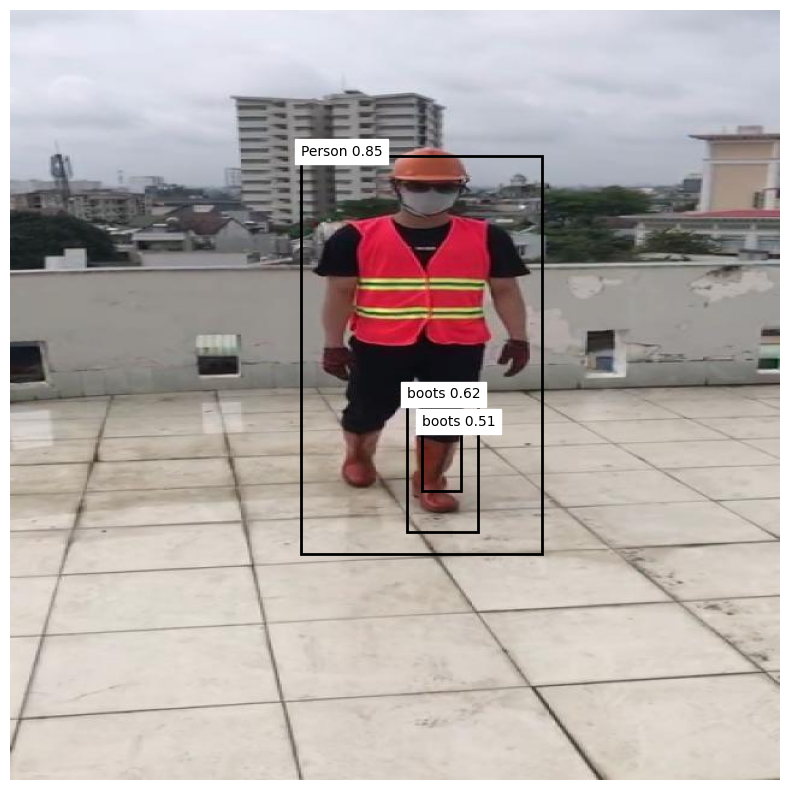

In [ ]:
# actual prediction
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Get the original validation image
image, target = val_dataset[0]

image_np = image.permute(1, 2, 0).numpy()

fig, ax = plt.subplots(figsize=(10, 10))

ax.imshow(image_np)

class_names = [
    "background",
    "helmet",
    "gloves",
    "vest",
    "boots",
    "goggles",
    "none",
    "Person",
    "no_helmet",
    "no_goggle",
    "no_gloves",
    "no_boots"
]

for box, label, score in zip(boxes, labels, scores):

    x1, y1, x2, y2 = box.cpu().numpy()

    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        linewidth=2
    )

    ax.add_patch(rect)

    ax.text(
        x1,
        y1,
        f"{class_names[label.item()]} {score.item():.2f}",
        fontsize=10,
        backgroundcolor="white"
    )

ax.axis("off")
plt.show()

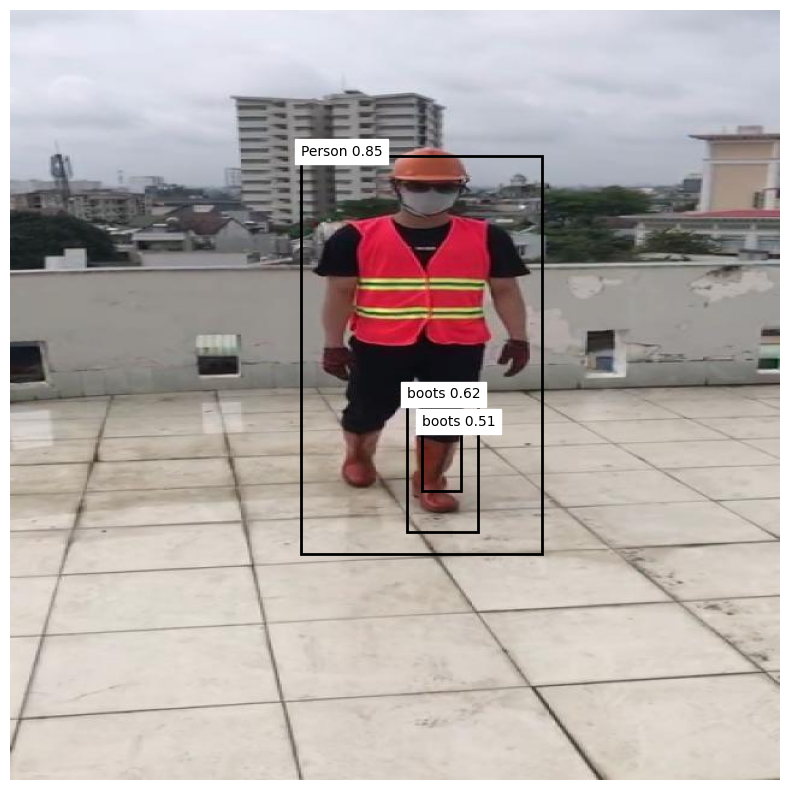

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

image, target = val_dataset[0]
image_np = image.permute(1, 2, 0).numpy()

class_names = [
    "background",
    "helmet",
    "gloves",
    "vest",
    "boots",
    "goggles",
    "none",
    "Person",
    "no_helmet",
    "no_goggle",
    "no_gloves",
    "no_boots"
]

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(image_np)

for box, label, score in zip(boxes, labels, scores):

    x1, y1, x2, y2 = box.cpu().numpy()

    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        linewidth=2
    )

    ax.add_patch(rect)

    ax.text(
        x1,
        y1,
        f"{class_names[label.item()]} {score.item():.2f}",
        fontsize=10,
        backgroundcolor="white"
    )

ax.axis("off")
plt.show()

In [ ]:
import torch

# Class names: Faster R-CNN uses 0 for background
class_names = [
    "background",
    "helmet",
    "gloves",
    "vest",
    "boots",
    "goggles",
    "none",
    "Person",
    "no_helmet",
    "no_goggle",
    "no_gloves",
    "no_boots"
]

num_classes = len(class_names)

# IoU threshold for considering a prediction a match
iou_threshold = 0.5

# Confidence threshold
score_threshold = 0.5


def calculate_iou(box1, box2):
    """
    Calculate IoU between two boxes.

    Box format:
    [x1, y1, x2, y2]
    """

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection_width = max(0, x2 - x1)
    intersection_height = max(0, y2 - y1)

    intersection = (
        intersection_width *
        intersection_height
    )

    area1 = (
        max(0, box1[2] - box1[0]) *
        max(0, box1[3] - box1[1])
    )

    area2 = (
        max(0, box2[2] - box2[0]) *
        max(0, box2[3] - box2[1])
    )

    union = area1 + area2 - intersection

    if union == 0:
        return 0.0

    return intersection / union

In [ ]:
# validation for all 143 images

# Make sure the model is in evaluation mode
model.eval()

# Counters for each class
true_positives = [0] * num_classes
false_positives = [0] * num_classes
false_negatives = [0] * num_classes

with torch.no_grad():

    for batch_idx, (images, targets) in enumerate(val_loader):

        images = [
            image.to(device)
            for image in images
        ]

        predictions = model(images)

        for prediction, target in zip(predictions, targets):

            # Move everything to CPU for evaluation
            pred_boxes = prediction["boxes"].cpu()
            pred_labels = prediction["labels"].cpu()
            pred_scores = prediction["scores"].cpu()

            gt_boxes = target["boxes"].cpu()
            gt_labels = target["labels"].cpu()

            # Confidence filtering
            keep = pred_scores >= score_threshold

            pred_boxes = pred_boxes[keep]
            pred_labels = pred_labels[keep]
            pred_scores = pred_scores[keep]

            # Track which ground-truth boxes have already been matched
            matched_gt = set()

            # Match predictions with ground truth
            for pred_box, pred_label in zip(
                pred_boxes,
                pred_labels
            ):

                pred_box = pred_box.tolist()
                pred_label = pred_label.item()

                best_iou = 0.0
                best_gt_index = -1

                for gt_index, (gt_box, gt_label) in enumerate(
                    zip(gt_boxes, gt_labels)
                ):

                    gt_label = gt_label.item()

                    # Classes must match
                    if pred_label != gt_label:
                        continue

                    # Ground truth already matched
                    if gt_index in matched_gt:
                        continue

                    iou = calculate_iou(
                        pred_box,
                        gt_box.tolist()
                    )

                    if iou > best_iou:
                        best_iou = iou
                        best_gt_index = gt_index

                # Successful detection
                if (
                    best_gt_index != -1
                    and best_iou >= iou_threshold
                ):
                    true_positives[pred_label] += 1
                    matched_gt.add(best_gt_index)

                # Wrong detection
                else:
                    false_positives[pred_label] += 1

            # Ground-truth objects that were not detected
            for gt_index, gt_label in enumerate(gt_labels):

                gt_label = gt_label.item()

                if gt_index not in matched_gt:
                    false_negatives[gt_label] += 1

        if (batch_idx + 1) % 20 == 0:
            print(
                f"Evaluated "
                f"{batch_idx + 1}/{len(val_loader)} images"
            )


print("\nEvaluation completed.")

Evaluated 20/143 images
Evaluated 40/143 images
Evaluated 60/143 images
Evaluated 80/143 images
Evaluated 100/143 images
Evaluated 120/143 images
Evaluated 140/143 images

Evaluation completed.


In [ ]:
# Calculate precision and recall for each class
# tabl printing cell
print("=" * 70)
print(f"{'Class':<15} {'TP':>6} {'FP':>6} {'FN':>6} {'Precision':>12} {'Recall':>12}")
print("=" * 70)

for class_id in range(1, num_classes):

    tp = true_positives[class_id]
    fp = false_positives[class_id]
    fn = false_negatives[class_id]

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0.0
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0.0
    )

    print(
        f"{class_names[class_id]:<15} "
        f"{tp:>6} "
        f"{fp:>6} "
        f"{fn:>6} "
        f"{precision:>12.3f} "
        f"{recall:>12.3f}"
    )

print("=" * 70)

Class               TP     FP     FN    Precision       Recall
helmet              79    413    122        0.161        0.393
gloves              41    322     95        0.113        0.301
vest                88   1007     83        0.080        0.515
boots               57    383     94        0.130        0.377
goggles             26     66     21        0.283        0.553
none                 2      3     79        0.400        0.025
Person             130    915    109        0.124        0.544
no_helmet            0      0     45        0.000        0.000
no_goggle            0      0     41        0.000        0.000
no_gloves            0      0     56        0.000        0.000
no_boots             0      0      4        0.000        0.000


In [ ]:
# another training epoch
model.train()

epoch_loss = 0.0

for batch_idx, (images, targets) in enumerate(train_loader):

    images = [image.to(device) for image in images]
    targets = [
        {k: v.to(device) for k, v in t.items()}
        for t in targets
    ]

    optimizer.zero_grad()

    loss_dict = model(images, targets)

    losses = sum(loss for loss in loss_dict.values())

    if not torch.isfinite(losses):
        print(f"Non-finite loss at batch {batch_idx + 1}")
        break

    losses.backward()

    # Prevent extremely large gradients
    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        max_norm=5.0
    )

    optimizer.step()

    epoch_loss += losses.item()

    if (batch_idx + 1) % 50 == 0:
        print(
            f"Batch {batch_idx + 1}/{len(train_loader)}: "
            f"{losses.item():.4f}"
        )

lr_scheduler.step()

average_loss = epoch_loss / len(train_loader)

print(f"\nEpoch completed")
print(f"Average Loss: {average_loss:.4f}")
print(f"Learning Rate: {optimizer.param_groups[0]['lr']}")

Batch 50/1132: 0.9432
Batch 100/1132: 1.0585
Batch 150/1132: 3.3450
Batch 200/1132: 0.8798
Batch 250/1132: 0.6966
Batch 300/1132: 0.8200
Batch 350/1132: 0.9293
Batch 400/1132: 1.7275
Batch 450/1132: 0.9426
Batch 500/1132: 0.7143
Batch 550/1132: 1.1255
Batch 600/1132: 0.9508
Batch 650/1132: 0.8925
Batch 700/1132: 2.4996
Batch 750/1132: 0.5366
Batch 800/1132: 1.9705
Batch 850/1132: 0.7659
Batch 900/1132: 0.6926
Batch 950/1132: 0.8934
Batch 1000/1132: 0.9331
Batch 1050/1132: 0.9066
Batch 1100/1132: 1.0405

Epoch completed
Average Loss: 1.0314
Learning Rate: 0.001


In [ ]:
from collections import Counter

train_class_counts = Counter()

for idx in range(len(train_dataset)):
    _, target = train_dataset[idx]

    for label in target["labels"]:
        train_class_counts[label.item()] += 1

print("=" * 45)
print(f"{'Class':<15} {'Training Objects':>20}")
print("=" * 45)

for class_id in range(1, num_classes):
    print(
        f"{class_names[class_id]:<15} "
        f"{train_class_counts[class_id]:>20}"
    )

print("=" * 45)

Class               Training Objects
helmet                          1341
gloves                          1146
vest                            1269
boots                           1235
goggles                          419
none                             651
Person                          1770
no_helmet                        400
no_goggle                        337
no_gloves                        442
no_boots                          88


In [ ]:
from collections import Counter

model.eval()

predicted_class_counts = Counter()

with torch.no_grad():
    for images, targets in val_loader:

        images = [image.to(device) for image in images]

        predictions = model(images)

        for prediction in predictions:
            labels = prediction["labels"].cpu().tolist()

            for label in labels:
                predicted_class_counts[label] += 1

print("=" * 50)
print(f"{'Class':<15} {'Predictions':>15}")
print("=" * 50)

for class_id in range(1, num_classes):
    print(
        f"{class_names[class_id]:<15} "
        f"{predicted_class_counts[class_id]:>15}"
    )

print("=" * 50)

Class               Predictions
helmet                     1117
gloves                      752
vest                       1706
boots                       860
goggles                     157
none                        363
Person                     1554
no_helmet                     3
no_goggle                     0
no_gloves                     0
no_boots                      0


In [ ]:
from collections import Counter

target_class_counts = Counter()

for idx in range(len(train_dataset)):
    _, target = train_dataset[idx]

    for label in target["labels"]:
        target_class_counts[label.item()] += 1

print("=" * 55)
print(f"{'Class ID':<10} {'Class Name':<15} {'Count':>15}")
print("=" * 55)

for class_id in range(1, num_classes):
    print(
        f"{class_id:<10} "
        f"{class_names[class_id]:<15} "
        f"{target_class_counts[class_id]:>15}"
    )

print("=" * 55)

Class ID   Class Name                Count
1          helmet                     1341
2          gloves                     1146
3          vest                       1269
4          boots                      1235
5          goggles                     419
6          none                        651
7          Person                     1770
8          no_helmet                   400
9          no_goggle                   337
10         no_gloves                   442
11         no_boots                     88


In [ ]:
import torch

model.eval()

violation_ids = {8, 9, 10, 11}

found = 0

with torch.no_grad():

    for images, targets in val_loader:

        images = [image.to(device) for image in images]
        predictions = model(images)

        for prediction, target in zip(predictions, targets):

            gt_labels = target["labels"]

            # Check whether this image contains a violation class
            has_violation = any(
                label.item() in violation_ids
                for label in gt_labels
            )

            if not has_violation:
                continue

            print("\n" + "=" * 70)

            print("Ground-truth violation classes:")

            for label in gt_labels:
                class_id = label.item()

                if class_id in violation_ids:
                    print(
                        f"  {class_id}: "
                        f"{class_names[class_id]}"
                    )

            print("\nTop predictions:")

            scores = prediction["scores"].cpu()
            labels = prediction["labels"].cpu()

            # Show top 15 predictions
            top_k = min(15, len(scores))

            for i in range(top_k):
                class_id = labels[i].item()

                print(
                    f"  {class_names[class_id]:<15} "
                    f"score={scores[i].item():.3f}"
                )

            found += 1

            if found >= 5:
                break

        if found >= 5:
            break

print("\nInspection completed.")


Ground-truth violation classes:
  9: no_goggle
  10: no_gloves
  10: no_gloves
  10: no_gloves
  9: no_goggle
  8: no_helmet
  8: no_helmet

Top predictions:
  Person          score=0.688
  Person          score=0.499
  helmet          score=0.217
  Person          score=0.203
  Person          score=0.163
  helmet          score=0.161
  Person          score=0.154
  helmet          score=0.151
  Person          score=0.142
  vest            score=0.109
  helmet          score=0.105
  Person          score=0.103
  helmet          score=0.099
  Person          score=0.094
  helmet          score=0.090

Ground-truth violation classes:
  10: no_gloves
  11: no_boots
  11: no_boots
  8: no_helmet
  9: no_goggle

Top predictions:
  vest            score=0.838
  Person          score=0.832
  boots           score=0.693
  helmet          score=0.262
  boots           score=0.227
  Person          score=0.205
  boots           score=0.203
  Person          score=0.193
  boots           score=

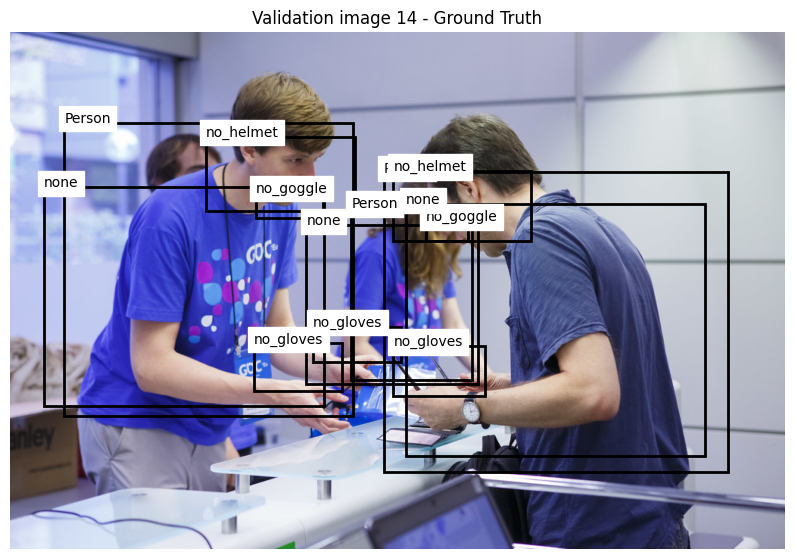

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

model.eval()

violation_ids = {8, 9, 10, 11}

for idx in range(len(val_dataset)):

    image, target = val_dataset[idx]

    labels = target["labels"]

    if not any(label.item() in violation_ids for label in labels):
        continue

    image_np = image.permute(1, 2, 0).numpy()

    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(image_np)

    for box, label in zip(
        target["boxes"],
        target["labels"]
    ):
        class_id = label.item()

        x1, y1, x2, y2 = box.tolist()

        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            linewidth=2
        )

        ax.add_patch(rect)

        ax.text(
            x1,
            y1,
            class_names[class_id],
            fontsize=10,
            backgroundcolor="white"
        )

    ax.set_title(
        f"Validation image {idx} - Ground Truth"
    )

    ax.axis("off")
    plt.show()

    break

In [ ]:
checkpoint = {
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "scheduler_state_dict": lr_scheduler.state_dict(),
    "epoch": 2
}

checkpoint_path = "/content/drive/MyDrive/ppe/fasterrcnn_checkpoint_epoch2.pth"

torch.save(checkpoint, checkpoint_path)

print("Checkpoint saved successfully!")

Checkpoint saved successfully!


In [ ]:
import os

checkpoint_path = "/content/drive/MyDrive/ppe/fasterrcnn_checkpoint_epoch2.pth"

print("Checkpoint exists:", os.path.exists(checkpoint_path))

if os.path.exists(checkpoint_path):
    print("Checkpoint size:",
          round(os.path.getsize(checkpoint_path) / (1024**3), 2),
          "GB")

Checkpoint exists: True
Checkpoint size: 0.31 GB


In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
CUDA available: True
GPU: Tesla T4


In [ ]:
## after reconnect
import torch
from torchvision.models.detection import fasterrcnn_resnet50_fpn

num_classes = 12

model = fasterrcnn_resnet50_fpn(
    weights=None,
    weights_backbone=None,
    num_classes=num_classes,
    min_size=512,
    max_size=512
)

model = model.to(device)

print("Model recreated.")
print(
    f"GPU allocated: "
    f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
)

Model recreated.
GPU allocated: 0.66 GB


In [ ]:
params = [
    p for p in model.parameters()
    if p.requires_grad
]

optimizer = torch.optim.SGD(
    params,
    lr=0.001,
    momentum=0.9,
    weight_decay=0.0005
)

lr_scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=3,
    gamma=0.1
)

print("Optimizer and scheduler recreated.")

Optimizer and scheduler recreated.


In [ ]:
# here we are loading the saved checkpoint

checkpoint_path = "/content/drive/MyDrive/ppe/fasterrcnn_checkpoint_epoch2.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device
)

model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
lr_scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

start_epoch = checkpoint["epoch"]

print("Checkpoint loaded successfully!")
print("Saved epoch:", start_epoch)
print("Current learning rate:", optimizer.param_groups[0]["lr"])

Checkpoint loaded successfully!
Saved epoch: 2
Current learning rate: 0.001


In [ ]:
# re creation of the data loader due to reconnection
train_dataset = ConstructionPPEDataset(
    root_dir="/content/drive/MyDrive/ppe",
    split="train"
)

train_loader = DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=2
)

print("Training images:", len(train_dataset))
print("Training batches:", len(train_loader))

Training images: 1132
Training batches: 1132


In [ ]:
model.train()

epoch_loss = 0.0

for batch_idx, (images, targets) in enumerate(train_loader):

    images = [image.to(device) for image in images]

    targets = [
        {k: v.to(device) for k, v in t.items()}
        for t in targets
    ]

    optimizer.zero_grad()

    loss_dict = model(images, targets)

    losses = sum(loss for loss in loss_dict.values())

    if not torch.isfinite(losses):
        print(f"Non-finite loss at batch {batch_idx + 1}")
        break

    losses.backward()

    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        max_norm=5.0
    )

    optimizer.step()

    epoch_loss += losses.item()

    if (batch_idx + 1) % 50 == 0:
        print(
            f"Batch {batch_idx + 1}/{len(train_loader)}: "
            f"{losses.item():.4f}"
        )

lr_scheduler.step()

average_loss = epoch_loss / len(train_loader)

print("\nEpoch 3 completed")
print(f"Average Loss: {average_loss:.4f}")
print(
    f"Learning Rate: "
    f"{optimizer.param_groups[0]['lr']}"
)

Batch 50/1132: 0.7535
Batch 100/1132: 0.9826
Batch 150/1132: 0.5792
Batch 200/1132: 0.6677
Batch 250/1132: 2.3784
Batch 300/1132: 1.0355
Batch 350/1132: 0.7048
Batch 400/1132: 2.5078
Batch 450/1132: 0.7262
Batch 500/1132: 1.7640
Batch 550/1132: 0.6378
Batch 600/1132: 0.9795
Batch 650/1132: 0.7821
Batch 700/1132: 0.9271
Batch 750/1132: 0.9524
Batch 800/1132: 0.7746
Batch 850/1132: 0.8411
Batch 900/1132: 2.1235
Batch 950/1132: 0.2809
Batch 1000/1132: 0.9291
Batch 1050/1132: 0.7809
Batch 1100/1132: 0.7440

Epoch 3 completed
Average Loss: 1.0203
Learning Rate: 0.001


In [ ]:
score_threshold = 0.5
iou_threshold = 0.5

# Run the validation cell you used for Epoch 2

In [ ]:
# validation for all 143 images

# Make sure the model is in evaluation mode
model.eval()

# Counters for each class
true_positives = [0] * num_classes
false_positives = [0] * num_classes
false_negatives = [0] * num_classes

with torch.no_grad():

    for batch_idx, (images, targets) in enumerate(val_loader):

        images = [
            image.to(device)
            for image in images
        ]

        predictions = model(images)

        for prediction, target in zip(predictions, targets):

            # Move everything to CPU for evaluation
            pred_boxes = prediction["boxes"].cpu()
            pred_labels = prediction["labels"].cpu()
            pred_scores = prediction["scores"].cpu()

            gt_boxes = target["boxes"].cpu()
            gt_labels = target["labels"].cpu()

            # Confidence filtering
            keep = pred_scores >= score_threshold

            pred_boxes = pred_boxes[keep]
            pred_labels = pred_labels[keep]
            pred_scores = pred_scores[keep]

            # Track which ground-truth boxes have already been matched
            matched_gt = set()

            # Match predictions with ground truth
            for pred_box, pred_label in zip(
                pred_boxes,
                pred_labels
            ):

                pred_box = pred_box.tolist()
                pred_label = pred_label.item()

                best_iou = 0.0
                best_gt_index = -1

                for gt_index, (gt_box, gt_label) in enumerate(
                    zip(gt_boxes, gt_labels)
                ):

                    gt_label = gt_label.item()

                    # Classes must match
                    if pred_label != gt_label:
                        continue

                    # Ground truth already matched
                    if gt_index in matched_gt:
                        continue

                    iou = calculate_iou(
                        pred_box,
                        gt_box.tolist()
                    )

                    if iou > best_iou:
                        best_iou = iou
                        best_gt_index = gt_index

                # Successful detection
                if (
                    best_gt_index != -1
                    and best_iou >= iou_threshold
                ):
                    true_positives[pred_label] += 1
                    matched_gt.add(best_gt_index)

                # Wrong detection
                else:
                    false_positives[pred_label] += 1

            # Ground-truth objects that were not detected
            for gt_index, gt_label in enumerate(gt_labels):

                gt_label = gt_label.item()

                if gt_index not in matched_gt:
                    false_negatives[gt_label] += 1

        if (batch_idx + 1) % 20 == 0:
            print(
                f"Evaluated "
                f"{batch_idx + 1}/{len(val_loader)} images"
            )


print("\nEvaluation completed.")

Evaluated 20/143 images
Evaluated 40/143 images
Evaluated 60/143 images
Evaluated 80/143 images
Evaluated 100/143 images
Evaluated 120/143 images
Evaluated 140/143 images

Evaluation completed.


In [ ]:
# Calculate precision and recall for each class
# tabl printing cell
print("=" * 70)
print(f"{'Class':<15} {'TP':>6} {'FP':>6} {'FN':>6} {'Precision':>12} {'Recall':>12}")
print("=" * 70)

for class_id in range(1, num_classes):

    tp = true_positives[class_id]
    fp = false_positives[class_id]
    fn = false_negatives[class_id]

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0.0
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0.0
    )

    print(
        f"{class_names[class_id]:<15} "
        f"{tp:>6} "
        f"{fp:>6} "
        f"{fn:>6} "
        f"{precision:>12.3f} "
        f"{recall:>12.3f}"
    )

print("=" * 70)

Class               TP     FP     FN    Precision       Recall
helmet              53     30    148        0.639        0.264
gloves              12      4    124        0.750        0.088
vest                87    370     84        0.190        0.509
boots               50     42    101        0.543        0.331
goggles             16     14     31        0.533        0.340
none                 0      0     81        0.000        0.000
Person              95    156    144        0.378        0.397
no_helmet            0      0     45        0.000        0.000
no_goggle            0      0     41        0.000        0.000
no_gloves            0      0     56        0.000        0.000
no_boots             0      0      4        0.000        0.000


In [ ]:
# diagnostic test result
import torch

model.eval()

class_names = {
    1: "helmet",
    2: "gloves",
    3: "vest",
    4: "boots",
    5: "goggles",
    6: "none",
    7: "Person",
    8: "no_helmet",
    9: "no_goggle",
    10: "no_gloves",
    11: "no_boots"
}

violation_classes = {
    8: "no_helmet",
    9: "no_goggle",
    10: "no_gloves",
    11: "no_boots"
}

def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union = area1 + area2 - intersection

    if union == 0:
        return 0.0

    return intersection / union


# Store diagnostic results
diagnostic_results = {
    class_id: {
        "gt_count": 0,
        "matched_iou_50": 0,
        "best_iou": [],
        "predicted_classes": []
    }
    for class_id in violation_classes
}


with torch.no_grad():

    for batch_idx, (images, targets) in enumerate(val_loader):

        images = [image.to(device) for image in images]

        predictions = model(images)

        for prediction, target in zip(predictions, targets):

            pred_boxes = prediction["boxes"].cpu()
            pred_labels = prediction["labels"].cpu()
            pred_scores = prediction["scores"].cpu()

            gt_boxes = target["boxes"].cpu()
            gt_labels = target["labels"].cpu()

            # Look only at reasonably confident predictions
            keep = pred_scores >= 0.05

            pred_boxes = pred_boxes[keep]
            pred_labels = pred_labels[keep]
            pred_scores = pred_scores[keep]

            # Check every violation ground-truth box
            for gt_box, gt_label in zip(gt_boxes, gt_labels):

                gt_label = gt_label.item()

                if gt_label not in violation_classes:
                    continue

                diagnostic_results[gt_label]["gt_count"] += 1

                best_iou = 0.0
                best_pred_class = None
                best_score = 0.0

                gt_box = gt_box.tolist()

                # Find prediction with highest IoU,
                # regardless of predicted class
                for pred_box, pred_label, pred_score in zip(
                    pred_boxes,
                    pred_labels,
                    pred_scores
                ):

                    iou = calculate_iou(
                        gt_box,
                        pred_box.tolist()
                    )

                    if iou > best_iou:
                        best_iou = iou
                        best_pred_class = pred_label.item()
                        best_score = pred_score.item()

                diagnostic_results[gt_label]["best_iou"].append(best_iou)

                if best_iou >= 0.5:
                    diagnostic_results[gt_label]["matched_iou_50"] += 1

                    if best_pred_class is not None:
                        diagnostic_results[gt_label]["predicted_classes"].append(
                            (
                                best_pred_class,
                                best_score
                            )
                        )


# Print results
print("=" * 80)
print("VIOLATION CLASS DIAGNOSTIC")
print("=" * 80)

for class_id, class_name in violation_classes.items():

    result = diagnostic_results[class_id]

    gt_count = result["gt_count"]
    matched = result["matched_iou_50"]

    if gt_count > 0:
        match_rate = matched / gt_count
        average_iou = sum(result["best_iou"]) / len(result["best_iou"])
        max_iou = max(result["best_iou"])
    else:
        match_rate = 0
        average_iou = 0
        max_iou = 0

    print(f"\n{class_name}")
    print(f"GT boxes          : {gt_count}")
    print(f"Best IoU >= 0.50  : {matched}")
    print(f"Match rate        : {match_rate:.3f}")
    print(f"Average best IoU  : {average_iou:.3f}")
    print(f"Maximum best IoU  : {max_iou:.3f}")

    # Count which classes are being predicted over violation regions
    confusion = {}

    for pred_class_id, score in result["predicted_classes"]:

        pred_name = class_names.get(
            pred_class_id,
            f"class_{pred_class_id}"
        )

        confusion[pred_name] = confusion.get(pred_name, 0) + 1

    if confusion:
        print("Predicted classes over matching regions:")

        for pred_name, count in sorted(
            confusion.items(),
            key=lambda x: x[1],
            reverse=True
        ):
            print(f"  {pred_name:<12} : {count}")

print("\n" + "=" * 80)

VIOLATION CLASS DIAGNOSTIC

no_helmet
GT boxes          : 45
Best IoU >= 0.50  : 15
Match rate        : 0.333
Average best IoU  : 0.358
Maximum best IoU  : 0.912
Predicted classes over matching regions:
  vest         : 6
  helmet       : 4
  boots        : 4
  gloves       : 1

no_goggle
GT boxes          : 41
Best IoU >= 0.50  : 1
Match rate        : 0.024
Average best IoU  : 0.148
Maximum best IoU  : 0.704
Predicted classes over matching regions:
  vest         : 1

no_gloves
GT boxes          : 56
Best IoU >= 0.50  : 2
Match rate        : 0.036
Average best IoU  : 0.135
Maximum best IoU  : 0.626
Predicted classes over matching regions:
  helmet       : 2

no_boots
GT boxes          : 4
Best IoU >= 0.50  : 0
Match rate        : 0.000
Average best IoU  : 0.074
Maximum best IoU  : 0.208



In [ ]:
checkpoint_path = "/content/drive/MyDrive/ppe/fasterrcnn_checkpoint_epoch3.pth"

torch.save({
    "epoch": 3,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "scheduler_state_dict": lr_scheduler.state_dict()
}, checkpoint_path)

print("Epoch 3 checkpoint saved!")

Epoch 3 checkpoint saved!


In [ ]:
# Lets start the experiment to
# pretrained faster RNN

In [ ]:
import torch
from torchvision.models import ResNet50_Weights
from torchvision.models.detection import fasterrcnn_resnet50_fpn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_pretrained = fasterrcnn_resnet50_fpn(
    weights=None,
    weights_backbone=ResNet50_Weights.DEFAULT,
    num_classes=12,
    min_size=512,
    max_size=512
)

model_pretrained = model_pretrained.to(device)

print("Device:", device)
print("Pretrained Faster R-CNN created successfully!")

if torch.cuda.is_available():
    print(
        f"GPU allocated: "
        f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
    )

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 132MB/s]


Device: cuda
Pretrained Faster R-CNN created successfully!
GPU allocated: 1.02 GB


In [ ]:
#new optimzer
params = [
    p for p in model_pretrained.parameters()
    if p.requires_grad
]

optimizer_pretrained = torch.optim.SGD(
    params,
    lr=0.001,
    momentum=0.9,
    weight_decay=0.0005
)

lr_scheduler_pretrained = torch.optim.lr_scheduler.StepLR(
    optimizer_pretrained,
    step_size=3,
    gamma=0.1
)

print("Optimizer ready.")
print("Learning rate:", optimizer_pretrained.param_groups[0]["lr"])

Optimizer ready.
Learning rate: 0.001


In [ ]:
model_pretrained.train()

images, targets = next(iter(train_loader))

images = [image.to(device) for image in images]
targets = [
    {k: v.to(device) for k, v in t.items()}
    for t in targets
]

optimizer_pretrained.zero_grad()

loss_dict = model_pretrained(images, targets)
losses = sum(loss for loss in loss_dict.values())

print("Loss components:")
for name, loss in loss_dict.items():
    print(f"{name}: {loss.item():.4f}")

print(f"Total loss: {losses.item():.4f}")

losses.backward()

torch.nn.utils.clip_grad_norm_(
    model_pretrained.parameters(),
    max_norm=5.0
)

optimizer_pretrained.step()

print("\nBackward + optimizer step: SUCCESS")

if torch.cuda.is_available():
    print(
        f"GPU allocated: "
        f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
    )
    print(
        f"GPU reserved: "
        f"{torch.cuda.memory_reserved() / 1024**3:.2f} GB"
    )

Loss components:
loss_classifier: 2.4135
loss_box_reg: 0.0200
loss_objectness: 0.7024
loss_rpn_box_reg: 0.0255
Total loss: 3.1613

Backward + optimizer step: SUCCESS
GPU allocated: 1.12 GB
GPU reserved: 1.63 GB


In [ ]:
model_pretrained.train()

epoch_loss = 0.0

for batch_idx, (images, targets) in enumerate(train_loader):

    images = [image.to(device) for image in images]

    targets = [
        {k: v.to(device) for k, v in t.items()}
        for t in targets
    ]

    optimizer_pretrained.zero_grad()

    loss_dict = model_pretrained(images, targets)
    losses = sum(loss for loss in loss_dict.values())

    # Safety check
    if not torch.isfinite(losses):
        print(f"Non-finite loss at batch {batch_idx + 1}")
        break

    losses.backward()

    # Prevent extremely large gradients
    torch.nn.utils.clip_grad_norm_(
        model_pretrained.parameters(),
        max_norm=5.0
    )

    optimizer_pretrained.step()

    epoch_loss += losses.item()

    if (batch_idx + 1) % 50 == 0:
        print(
            f"Batch {batch_idx + 1}/{len(train_loader)} "
            f"- Loss: {losses.item():.4f}"
        )

lr_scheduler_pretrained.step()

average_loss = epoch_loss / len(train_loader)

print("\n" + "=" * 60)
print("PRETRAINED FASTER R-CNN - EPOCH 1 COMPLETE")
print("=" * 60)
print(f"Average Loss: {average_loss:.4f}")
print(
    f"Learning Rate: "
    f"{optimizer_pretrained.param_groups[0]['lr']}"
)